
# Digital Archaeology of Wikipedia
## Initial Exploratory Data Analysis & Visualization

**Project:** Analyzing Historical Changes to Wikipedia Event Pages

**Objective:** Examine how Wikipedia articles about major historical events have evolved through their revision histories.

This notebook explores:

1. Dataset coverage and quality
2. Historical revision activity
3. Differences in editing activity across articles
4. Article growth and size changes
5. Contributor behavior and participation
6. Editing intensity and unusual activity periods
7. Comparative patterns across historical events

### Data sources

- `historical_revisions_cleaned.csv` — primary cleaned revision dataset
- `article_summary.csv` — article-level summary
- `monthly_activity.csv` — monthly revision activity, if available
- `largest_observed_changes.csv` — largest article-size changes, if available

### Important methodological note

Article-size differences measure changes in revision size, not necessarily the exact amount of text added or removed. The current dataset contains revision metadata rather than full revision text.

All findings in this notebook are exploratory and should be validated before being presented as historical conclusions.


In [1]:

from pathlib import Path
import warnings
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mticker
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)

# --------------------------------------------------
# PATH CONFIGURATION
# --------------------------------------------------

BASE = Path(r"C:\Users\Jackson\Desktop\class\arch\finalProject\historical_analysis")

DATA_DIR = BASE / "cleaned"

OUTPUT_DIR = Path(r"C:\Users\Jackson\Desktop\class\arch\finalProject\analysis")
FIGURES = OUTPUT_DIR / "figures"
RESULTS = OUTPUT_DIR / "analysis_results"

FIGURES.mkdir(exist_ok=True)
RESULTS.mkdir(exist_ok=True)

DATA_PATH = DATA_DIR / "historical_revisions_cleaned.csv"
SUMMARY_PATH = DATA_DIR / "article_summary.csv"

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH}. Update BASE to your project directory."
    )

# --------------------------------------------------
# VISUALIZATION CONFIGURATION
# --------------------------------------------------

BG = "#101827"
PANEL = "#192438"
GRID = "#344258"
TEXT = "#F1F5F9"
MUTED = "#A5B4C7"

COLORS = [
    "#55D6BE",
    "#61A5FF",
    "#F6BD60",
    "#C792EA",
    "#FF7B89",
    "#8BD17C",
    "#F08A5D",
    "#82C0CC",
    "#D4A5A5",
    "#B8C0FF",
]

plt.rcParams.update({
    "figure.facecolor": BG,
    "axes.facecolor": PANEL,
    "axes.edgecolor": GRID,
    "axes.labelcolor": TEXT,
    "axes.titlecolor": TEXT,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "text.color": TEXT,
    "grid.color": GRID,
    "grid.alpha": 0.45,
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 15,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "legend.facecolor": PANEL,
    "legend.edgecolor": GRID,
    "savefig.facecolor": BG,
    "savefig.dpi": 300,
})

def finish_plot(fig, filename):
    fig.tight_layout()
    fig.savefig(
        FIGURES / filename,
        dpi=300,
        bbox_inches="tight",
        facecolor=BG
    )
    plt.show()
    plt.close(fig)

def format_count(value):
    return f"{value:,.0f}"

print("Visualization environment initialized.")
print("Project directory:", BASE.resolve())
print("Figures directory:", FIGURES.resolve())


Visualization environment initialized.
Project directory: C:\Users\Jackson\Desktop\class\arch\finalProject\historical_analysis
Figures directory: C:\Users\Jackson\Desktop\class\arch\finalProject\analysis\figures


In [2]:

df = pd.read_csv(
    DATA_PATH,
    low_memory=False
)

# Standardize timestamps
df["timestamp"] = pd.to_datetime(
    df["timestamp"],
    utc=True,
    errors="coerce"
)

# Standardize numeric columns
for col in ["revision_id", "parent_id", "article_size_bytes", "user_id"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Standardize boolean fields
def to_boolean(series):
    return (
        series.astype(str)
        .str.lower()
        .isin(["true", "1", "yes"])
    )

df["is_minor"] = to_boolean(df["is_minor"])

# Normalize text fields
df["article_title"] = df["article_title"].fillna("Unknown article")
df["username"] = df["username"].fillna("Unknown")
df["edit_comment"] = df["edit_comment"].fillna("")

# Ensure valid chronological records
df = df.dropna(
    subset=["timestamp", "article_size_bytes", "revision_id"]
).copy()

df = df[df["article_size_bytes"] >= 0]

df["year"] = df["timestamp"].dt.year
df["month"] = df["timestamp"].dt.to_period("M").astype(str)
df["date"] = df["timestamp"].dt.date

df = df.sort_values(
    ["article_title", "timestamp", "revision_id"]
).reset_index(drop=True)

# Recalculate size changes to ensure chronological consistency
df["size_change"] = (
    df.groupby("article_title")["article_size_bytes"].diff()
)

df["absolute_size_change"] = df["size_change"].abs()

df["size_change_percentage"] = (
    df.groupby("article_title")["article_size_bytes"]
    .pct_change(fill_method=None) * 100
)

print(f"Loaded {len(df):,} valid revisions.")
print(f"Articles: {df['article_title'].nunique():,}")
print(f"Date range: {df['timestamp'].min()} to {df['timestamp'].max()}")
print(f"Unique usernames: {df['username'].nunique():,}")

display(df.head())


C:\Users\Jackson\AppData\Local\Temp\ipykernel_31768\399856703.py:41: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df["month"] = df["timestamp"].dt.to_period("M").astype(str)


Loaded 313,269 valid revisions.
Articles: 31
Date range: 2001-05-14 08:28:10+00:00 to 2026-11-10 06:27:03+00:00
Unique usernames: 88,233


,article_title,revision_id,parent_id,timestamp,username,user_id,edit_comment,article_size_bytes,is_minor,user_hidden,comment_hidden,year,month,sampled_size_change,date,size_change,absolute_size_change,size_change_percentage
0,American Civil War,334930481,334189771,2001-11-02 23:28:55+00:00,M. Comer,10959232.0,*Added mention of battles in the Western theat...,4927,True,False,False,2001,2001-11,NaN,2001-11-02,NaN,NaN,NaN
1,American Civil War,334930482,334930481,2001-11-03 00:22:24+00:00,TimShell,4938.0,*,4998,True,False,False,2001,2001-11,71.0,2001-11-03,71.0,71.0,1.441039
2,American Civil War,234266,334930482,2001-12-06 08:28:38+00:00,193.133.134.xxx,0.0,*,5077,True,False,False,2001,2001-12,79.0,2001-12-06,79.0,79.0,1.580632
3,American Civil War,234267,234266,2002-01-11 00:26:43+00:00,Doug McNaught,9014740.0,"Added links, made some corrections and additions",5464,True,False,False,2002,2002-01,387.0,2002-01-11,387.0,387.0,7.622612
4,American Civil War,234268,234267,2002-01-14 14:53:49+00:00,Szopen,72.0,*,5519,True,False,False,2002,2002-01,55.0,2002-01-14,55.0,55.0,1.006589


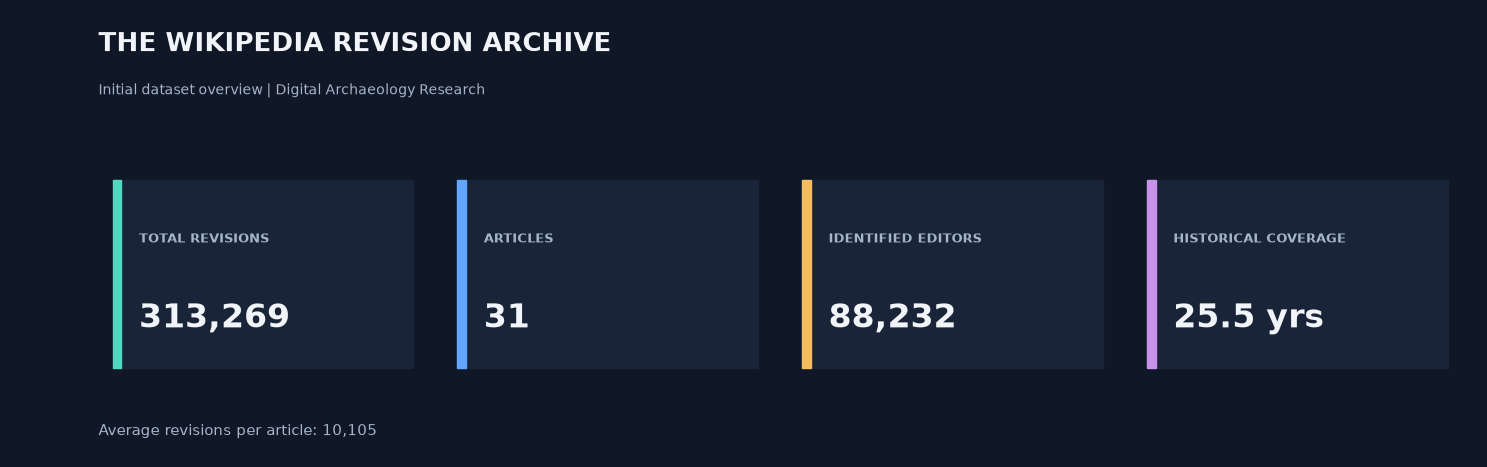

In [3]:

total_revisions = len(df)
total_articles = df["article_title"].nunique()
total_editors = df.loc[df["username"] != "Unknown", "username"].nunique()

date_range_days = (
    df["timestamp"].max() - df["timestamp"].min()
).days

total_years = date_range_days / 365.25

avg_revisions = total_revisions / max(total_articles, 1)

fig, ax = plt.subplots(figsize=(15, 4.8))
ax.set_xlim(0, 15)
ax.set_ylim(0, 4.8)
ax.axis("off")

fig.text(
    0.07, 0.88,
    "THE WIKIPEDIA REVISION ARCHIVE",
    fontsize=19, weight="bold", color=TEXT
)

fig.text(
    0.07, 0.79,
    "Initial dataset overview | Digital Archaeology Research",
    fontsize=10, color=MUTED
)

metrics = [
    ("TOTAL REVISIONS", f"{total_revisions:,}", COLORS[0]),
    ("ARTICLES", f"{total_articles:,}", COLORS[1]),
    ("IDENTIFIED EDITORS", f"{total_editors:,}", COLORS[2]),
    ("HISTORICAL COVERAGE", f"{total_years:.1f} yrs", COLORS[3]),
]

for i, (label, value, color) in enumerate(metrics):
    x = 0.07 + i * 0.235

    ax.add_patch(plt.Rectangle(
        (x, 0.20), 0.205, 0.42,
        color=PANEL,
        transform=ax.transAxes
    ))

    ax.add_patch(plt.Rectangle(
        (x, 0.20), 0.006, 0.42,
        color=color,
        transform=ax.transAxes
    ))

    ax.text(
        x + 0.018, 0.48, label,
        transform=ax.transAxes,
        fontsize=9, color=MUTED, weight="bold"
    )

    ax.text(
        x + 0.018, 0.29, value,
        transform=ax.transAxes,
        fontsize=24, color=TEXT, weight="bold"
    )

fig.text(
    0.07, 0.08,
    f"Average revisions per article: {avg_revisions:,.0f}",
    fontsize=11, color=MUTED
)

finish_plot(fig, "01_dataset_overview.png")


,Missing,Missing %,Unique values
article_title,0,0.0,31
revision_id,0,0.0,313269
parent_id,0,0.0,313197
timestamp,0,0.0,313038
username,0,0.0,88233
user_id,11,0.0,35277
edit_comment,0,0.0,155922
article_size_bytes,0,0.0,142850
is_minor,0,0.0,1


Duplicate revision IDs: 0
Negative article sizes: 0
Missing timestamps: 0


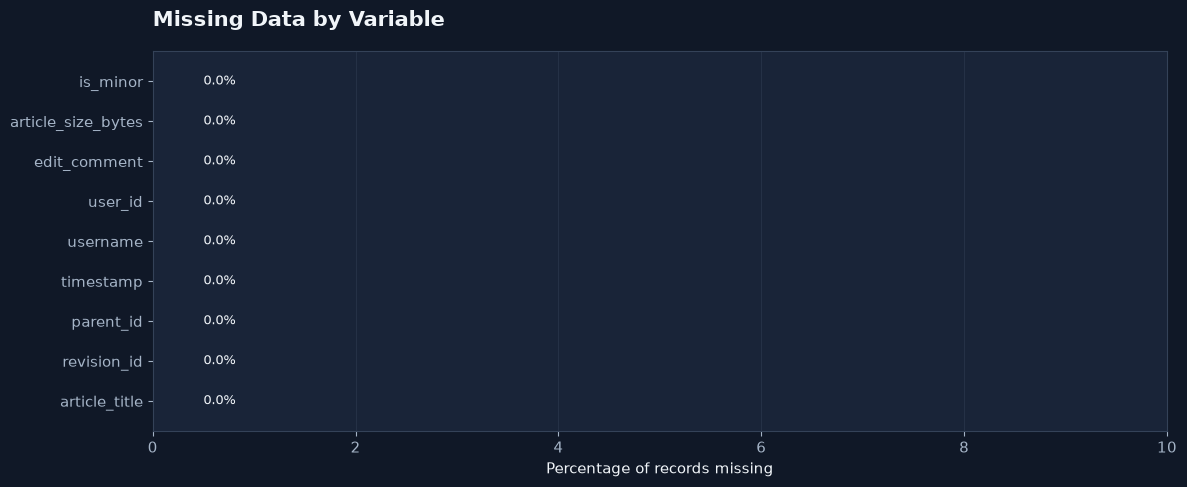

In [4]:

quality_columns = [
    "article_title",
    "revision_id",
    "parent_id",
    "timestamp",
    "username",
    "user_id",
    "edit_comment",
    "article_size_bytes",
    "is_minor"
]

quality = pd.DataFrame({
    "Missing": df[quality_columns].isna().sum(),
    "Missing %": (
        df[quality_columns].isna().mean() * 100
    ).round(2),
    "Unique values": df[quality_columns].nunique()
})

display(quality)

print("Duplicate revision IDs:", df["revision_id"].duplicated().sum())
print("Negative article sizes:", (df["article_size_bytes"] < 0).sum())
print("Missing timestamps:", df["timestamp"].isna().sum())

quality.to_csv(RESULTS / "data_quality_report.csv")

fig, ax = plt.subplots(figsize=(12, 5))

missing = quality["Missing %"].sort_values()

bars = ax.barh(
    missing.index,
    missing.values,
    color=COLORS[1],
    height=0.65
)

for bar, value in zip(bars, missing.values):
    ax.text(
        value + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.1f}%",
        va="center",
        fontsize=9,
        color=TEXT
    )

ax.set_title("Missing Data by Variable", loc="left", pad=18)
ax.set_xlabel("Percentage of records missing")
ax.set_xlim(0, max(10, missing.max() * 1.2))
ax.grid(axis="x")

finish_plot(fig, "02_data_quality.png")


,article,revisions,percentage,cumulative_percentage
0,World War II,28609,9.132407,9.132407
1,September 11 attacks,22585,7.209459,16.341866
2,World War I,20277,6.472712,22.814578
3,Vietnam War,19378,6.185738,29.000316
4,Assassination of John F. Kennedy,15182,4.846314,33.846630
5,American Civil War,14930,4.765872,38.612502
6,Korean War,14749,4.708094,43.320597
7,Gulf War,14132,4.511139,47.831736
8,Cold War,12602,4.022741,51.854477
9,Great Depression,11555,3.688523,55.543000


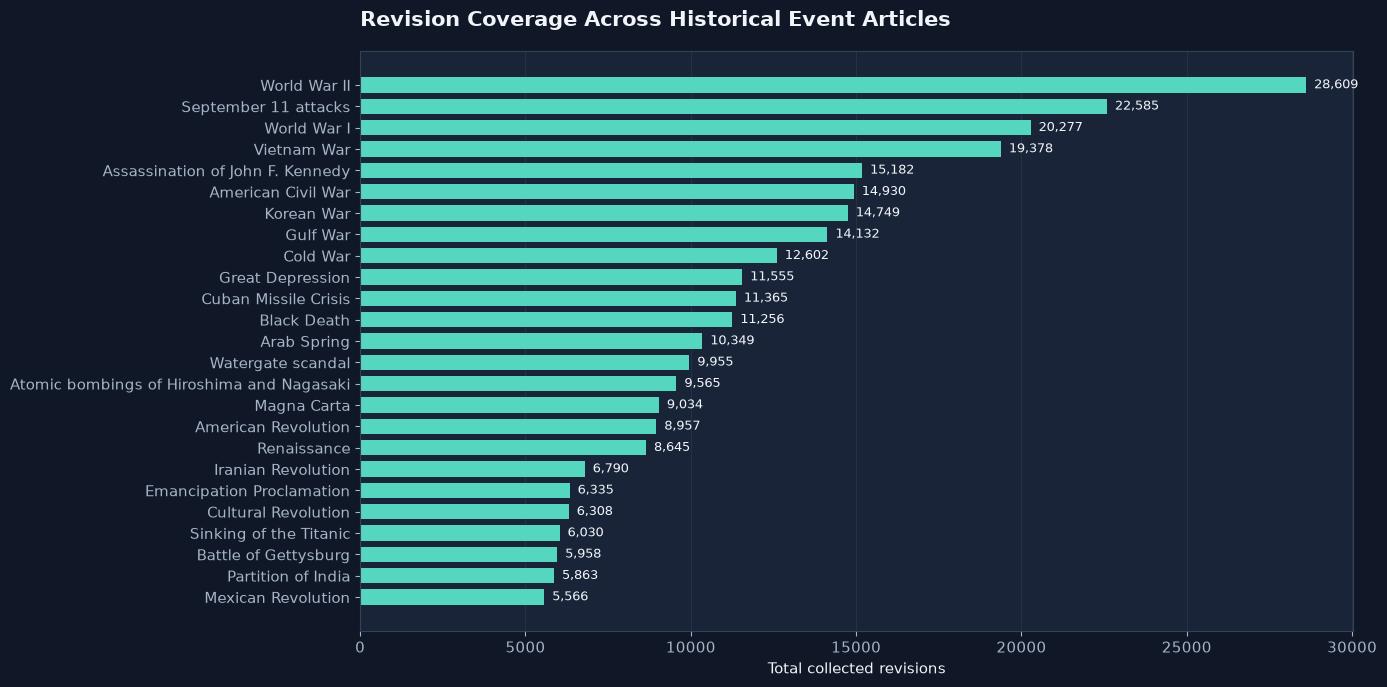

In [5]:

article_counts = (
    df.groupby("article_title")
    .size()
    .sort_values(ascending=False)
)

coverage = pd.DataFrame({
    "article": article_counts.index,
    "revisions": article_counts.values
})

coverage["percentage"] = (
    coverage["revisions"] / total_revisions * 100
)

coverage["cumulative_percentage"] = (
    coverage["percentage"].cumsum()
)

display(coverage)

coverage.to_csv(
    RESULTS / "article_revision_coverage.csv",
    index=False
)

fig, ax = plt.subplots(figsize=(14, 7))

plot_data = coverage.head(25).sort_values("revisions")

bars = ax.barh(
    plot_data["article"],
    plot_data["revisions"],
    color=COLORS[0],
    height=0.72
)

for bar, value in zip(bars, plot_data["revisions"]):
    ax.text(
        value,
        bar.get_y() + bar.get_height() / 2,
        f"  {value:,}",
        va="center",
        color=TEXT,
        fontsize=9
    )

ax.set_title(
    "Revision Coverage Across Historical Event Articles",
    loc="left",
    pad=18
)
ax.set_xlabel("Total collected revisions")
ax.grid(axis="x")
ax.set_axisbelow(True)

finish_plot(fig, "03_article_revision_coverage.png")


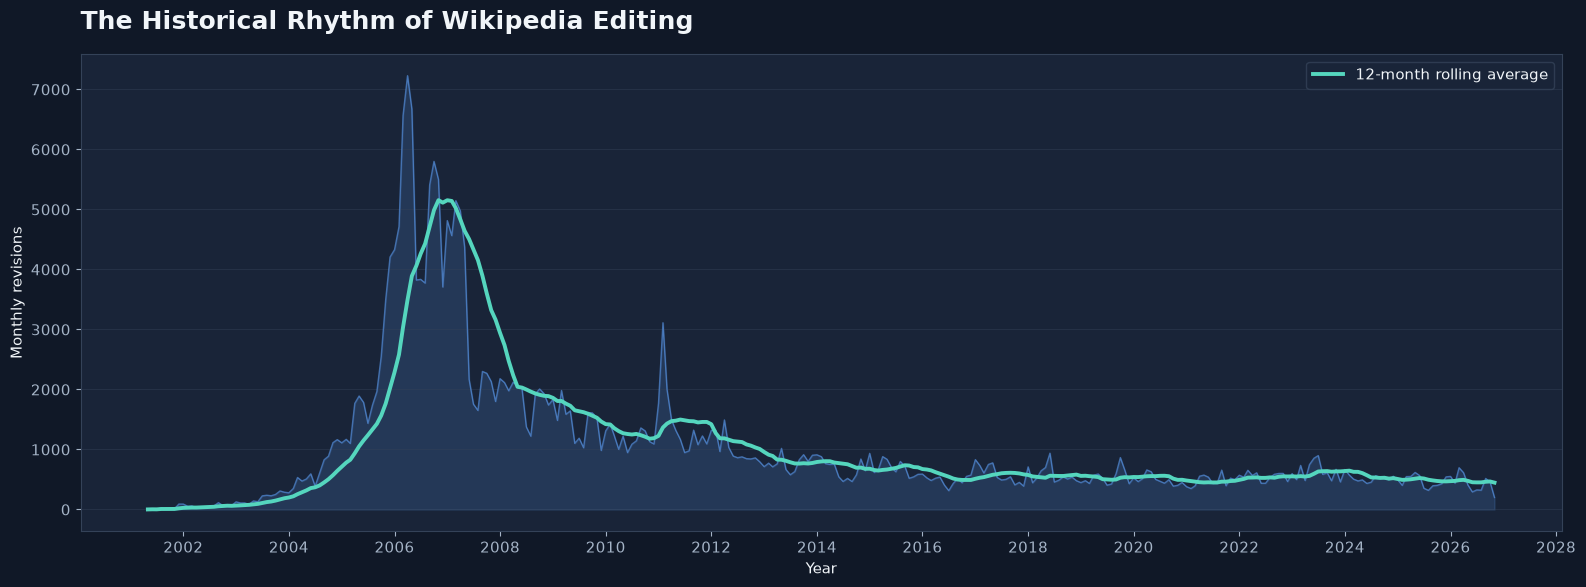

In [6]:

monthly = (
    df.groupby(pd.Grouper(key="timestamp", freq="MS"))
    .size()
    .rename("revisions")
    .reset_index()
)

monthly["rolling_average"] = (
    monthly["revisions"]
    .rolling(12, min_periods=1)
    .mean()
)

monthly.to_csv(
    RESULTS / "overall_monthly_activity.csv",
    index=False
)

fig, ax = plt.subplots(figsize=(16, 6))

ax.fill_between(
    monthly["timestamp"],
    monthly["revisions"],
    color=COLORS[1],
    alpha=0.16
)

ax.plot(
    monthly["timestamp"],
    monthly["revisions"],
    color=COLORS[1],
    alpha=0.55,
    linewidth=1
)

ax.plot(
    monthly["timestamp"],
    monthly["rolling_average"],
    color=COLORS[0],
    linewidth=2.8,
    label="12-month rolling average"
)

ax.set_title(
    "The Historical Rhythm of Wikipedia Editing",
    loc="left",
    pad=18,
    fontsize=18
)

ax.set_xlabel("Year")
ax.set_ylabel("Monthly revisions")

ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

ax.grid(axis="y")
ax.legend()

finish_plot(fig, "04_overall_revision_timeline.png")


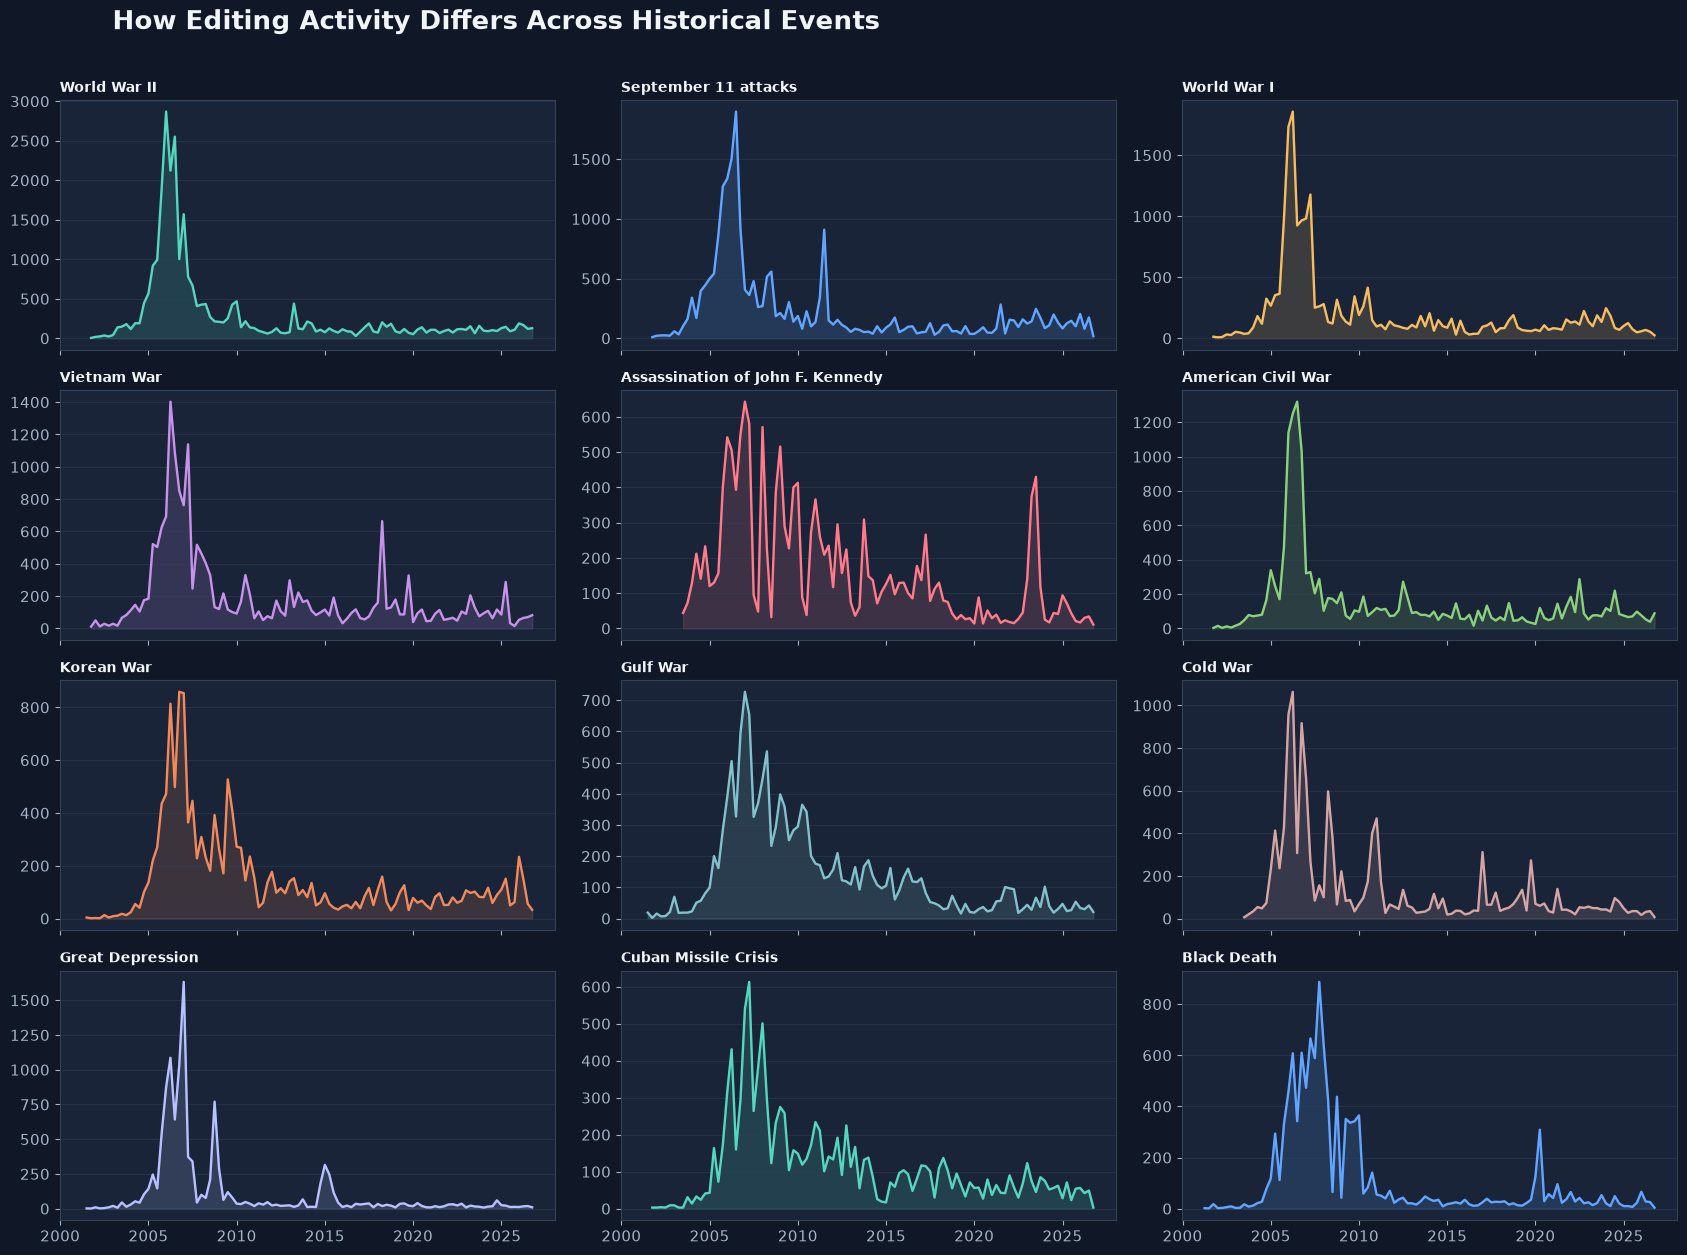

In [7]:

article_monthly = (
    df.groupby([
        "article_title",
        pd.Grouper(key="timestamp", freq="QS")
    ])
    .size()
    .rename("revisions")
    .reset_index()
)

top_articles = article_counts.head(12).index.tolist()

ncols = 3
nrows = int(np.ceil(len(top_articles) / ncols))

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(17, nrows * 3.1),
    sharex=True
)

axes = np.array(axes).flatten()

for i, article in enumerate(top_articles):
    ax = axes[i]

    data = article_monthly[
        article_monthly["article_title"] == article
    ]

    ax.fill_between(
        data["timestamp"],
        data["revisions"],
        color=COLORS[i % len(COLORS)],
        alpha=0.16
    )

    ax.plot(
        data["timestamp"],
        data["revisions"],
        color=COLORS[i % len(COLORS)],
        linewidth=1.7
    )

    ax.set_title(article, fontsize=10, loc="left")
    ax.grid(axis="y")

    ax.xaxis.set_major_locator(mdates.YearLocator(5))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

for ax in axes[len(top_articles):]:
    ax.set_visible(False)

fig.suptitle(
    "How Editing Activity Differs Across Historical Events",
    fontsize=19,
    weight="bold",
    color=TEXT,
    x=0.07,
    ha="left",
    y=1.01
)

finish_plot(fig, "05_article_activity_small_multiples.png")

article_monthly.to_csv(
    RESULTS / "article_quarterly_activity.csv",
    index=False
)


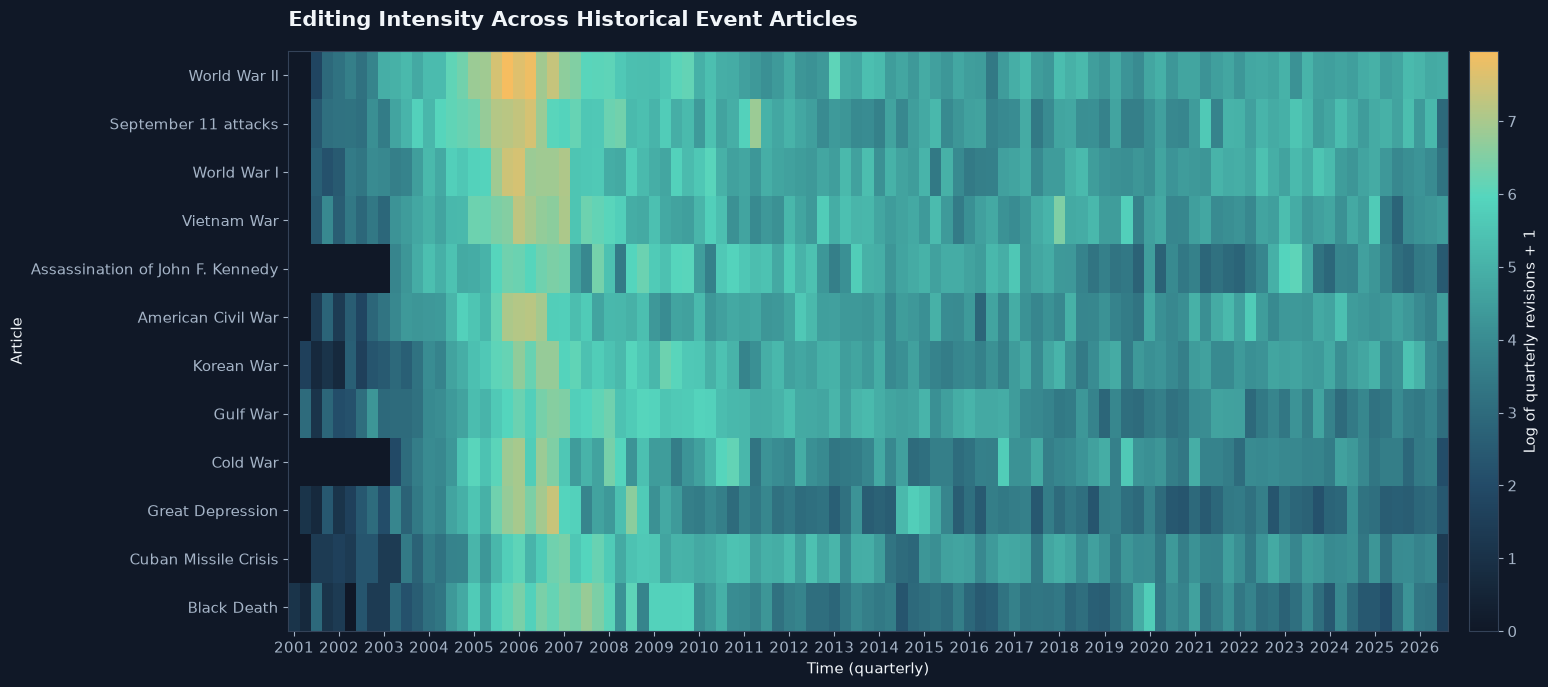

In [8]:

heatmap_data = (
    article_monthly[
        article_monthly["article_title"].isin(top_articles)
    ]
    .pivot_table(
        index="article_title",
        columns="timestamp",
        values="revisions",
        aggfunc="sum",
        fill_value=0
    )
)

heatmap_data = heatmap_data.reindex(top_articles)

log_data = np.log1p(heatmap_data)

cmap = LinearSegmentedColormap.from_list(
    "research_heat",
    [BG, "#234B68", "#398B91", "#55D6BE", "#F6BD60"]
)

fig, ax = plt.subplots(figsize=(17, 7))

im = ax.imshow(
    log_data.values,
    aspect="auto",
    cmap=cmap,
    interpolation="nearest"
)

ax.set_yticks(range(len(heatmap_data.index)))
ax.set_yticklabels(heatmap_data.index)

# Show approximately one label every four quarters
positions = np.arange(0, len(heatmap_data.columns), 4)

ax.set_xticks(positions)
ax.set_xticklabels([
    heatmap_data.columns[i].strftime("%Y")
    for i in positions
])

ax.set_title(
    "Editing Intensity Across Historical Event Articles",
    loc="left",
    pad=18
)

ax.set_xlabel("Time (quarterly)")
ax.set_ylabel("Article")

cbar = fig.colorbar(im, ax=ax, pad=0.015)
cbar.set_label("Log of quarterly revisions + 1")

finish_plot(fig, "06_revision_activity_heatmap.png")


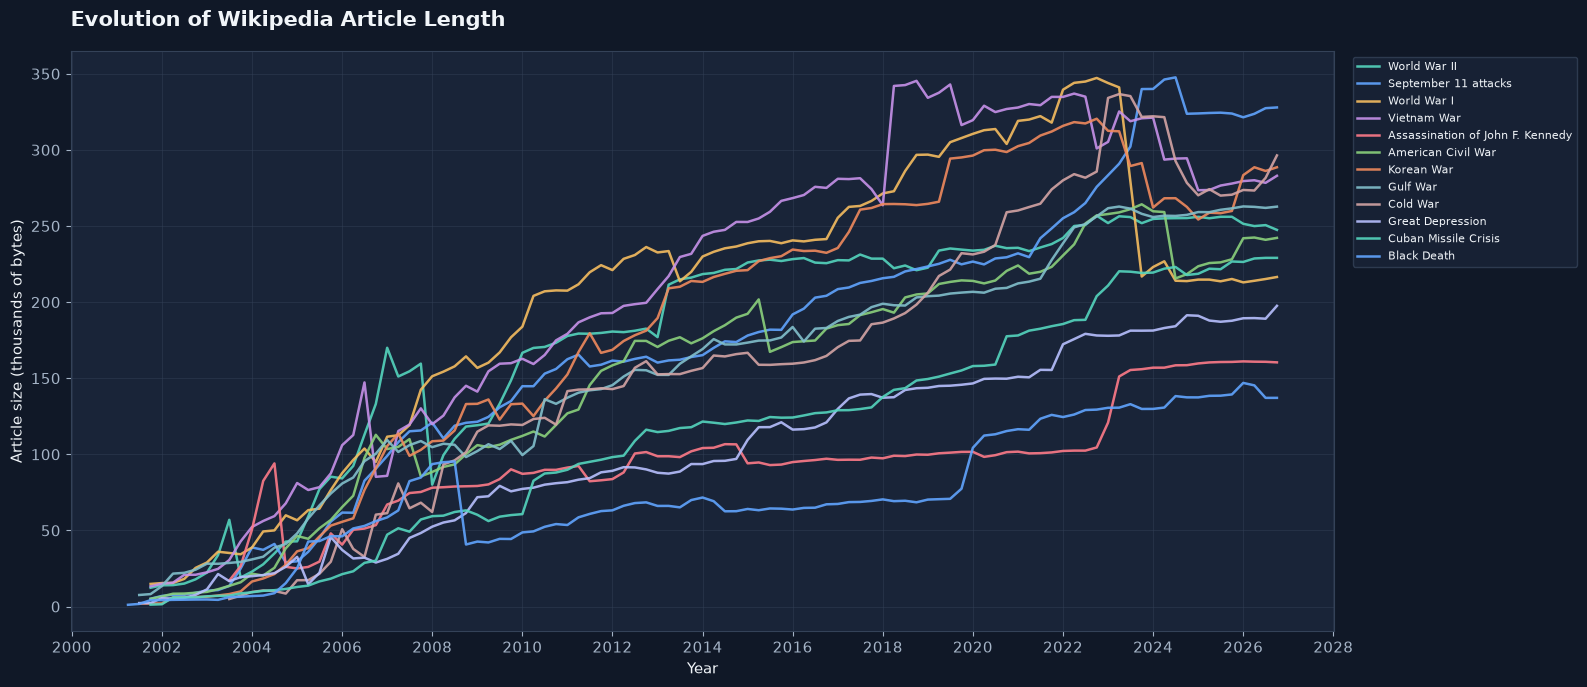

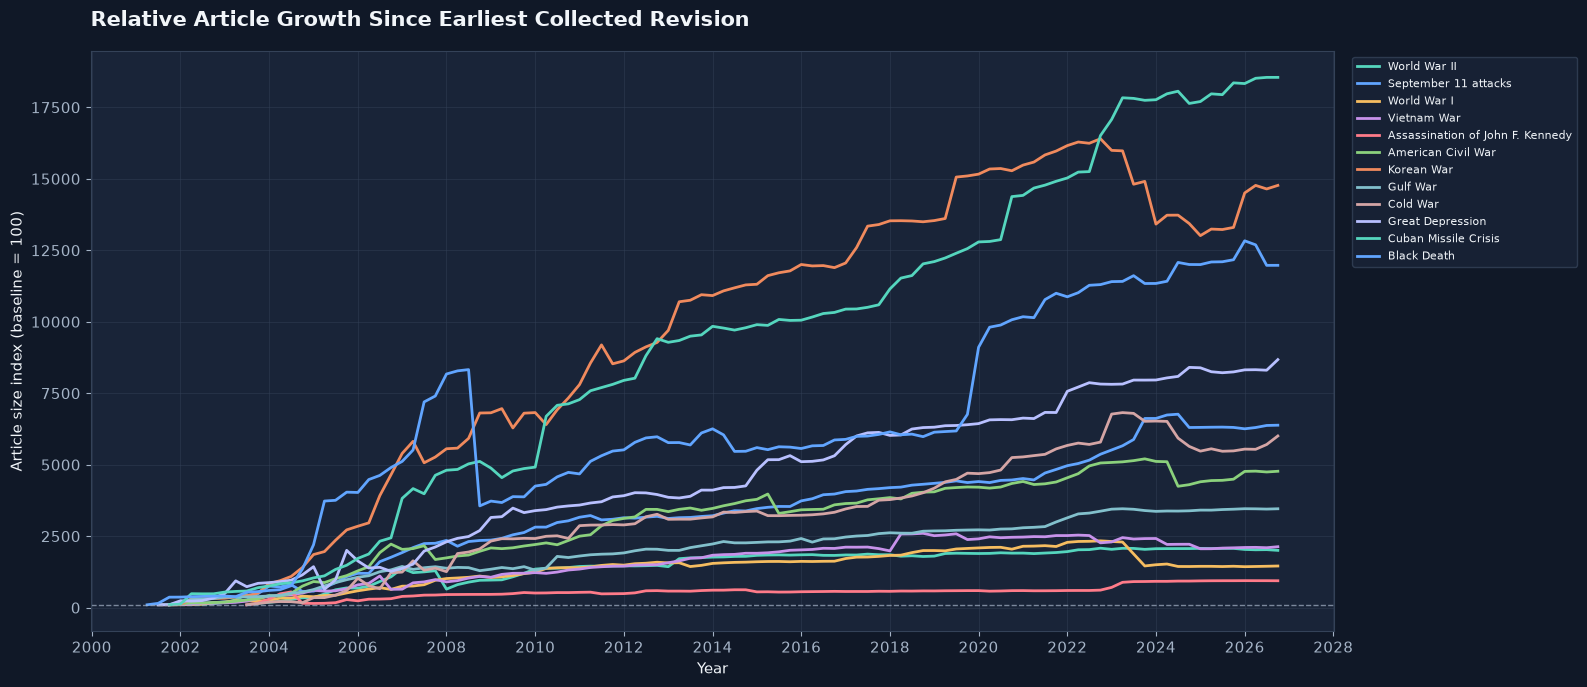

In [9]:

growth = (
    df.sort_values("timestamp")
    .groupby(["article_title", pd.Grouper(
        key="timestamp", freq="QS"
    )])
    .agg(
        article_size_bytes=("article_size_bytes", "last")
    )
    .reset_index()
    .dropna()
)

fig, ax = plt.subplots(figsize=(16, 7))

for i, article in enumerate(top_articles):
    data = growth[growth["article_title"] == article]

    if len(data) < 2:
        continue

    ax.plot(
        data["timestamp"],
        data["article_size_bytes"] / 1000,
        color=COLORS[i % len(COLORS)],
        linewidth=1.8,
        label=article,
        alpha=0.9
    )

ax.set_title(
    "Evolution of Wikipedia Article Length",
    loc="left",
    pad=18
)

ax.set_ylabel("Article size (thousands of bytes)")
ax.set_xlabel("Year")
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

ax.grid()
ax.legend(
    loc="upper left",
    bbox_to_anchor=(1.01, 1),
    fontsize=8
)

finish_plot(fig, "07_article_growth_absolute.png")

# --------------------------------------------------
# Indexed growth
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(16, 7))

for i, article in enumerate(top_articles):
    data = growth[
        growth["article_title"] == article
    ].sort_values("timestamp").copy()

    if len(data) < 2:
        continue

    baseline = data["article_size_bytes"].iloc[0]

    if baseline <= 0:
        continue

    data["indexed_size"] = (
        data["article_size_bytes"] / baseline * 100
    )

    ax.plot(
        data["timestamp"],
        data["indexed_size"],
        linewidth=2,
        color=COLORS[i % len(COLORS)],
        label=article
    )

ax.axhline(
    100,
    color=MUTED,
    linestyle="--",
    alpha=0.7,
    linewidth=1
)

ax.set_title(
    "Relative Article Growth Since Earliest Collected Revision",
    loc="left",
    pad=18
)

ax.set_ylabel("Article size index (baseline = 100)")
ax.set_xlabel("Year")
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

ax.grid()
ax.legend(
    loc="upper left",
    bbox_to_anchor=(1.01, 1),
    fontsize=8
)

finish_plot(fig, "08_article_growth_indexed.png")

growth.to_csv(
    RESULTS / "quarterly_article_growth.csv",
    index=False
)


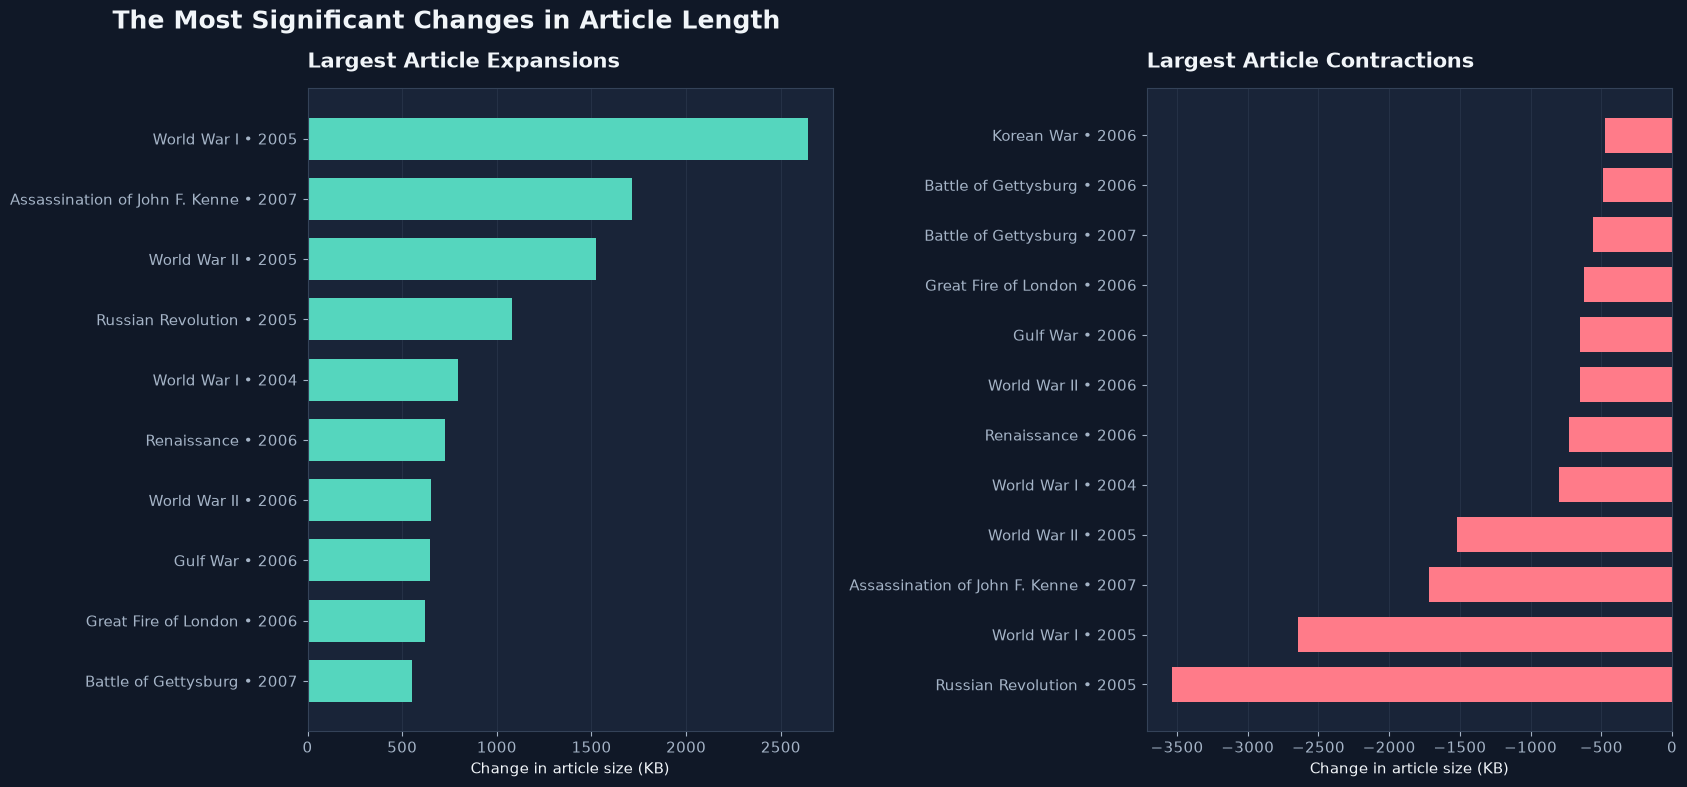

In [10]:

changes = df.dropna(subset=["size_change"]).copy()

largest_additions = (
    changes[changes["size_change"] > 0]
    .nlargest(15, "size_change")
)

largest_removals = (
    changes[changes["size_change"] < 0]
    .nsmallest(15, "size_change")
)

fig, axes = plt.subplots(
    1, 2,
    figsize=(17, 8)
)

for ax, data, title, color in [
    (
        axes[0],
        largest_additions.sort_values("size_change"),
        "Largest Article Expansions",
        COLORS[0]
    ),
    (
        axes[1],
        largest_removals.sort_values("size_change"),
        "Largest Article Contractions",
        COLORS[4]
    )
]:
    labels = [
        f"{row.article_title[:30]} • {row.timestamp.year}"
        for row in data.itertuples()
    ]

    bars = ax.barh(
        labels,
        data["size_change"] / 1000,
        color=color,
        height=0.7
    )

    ax.set_title(title, loc="left", pad=15)
    ax.set_xlabel("Change in article size (KB)")
    ax.grid(axis="x")
    ax.set_axisbelow(True)

fig.suptitle(
    "The Most Significant Changes in Article Length",
    fontsize=18,
    weight="bold",
    color=TEXT,
    x=0.07,
    ha="left"
)

finish_plot(fig, "09_largest_size_changes.png")

# Export complete ranked results
changes.nlargest(100, "absolute_size_change")[
    [
        "article_title",
        "revision_id",
        "timestamp",
        "username",
        "size_change",
        "absolute_size_change",
        "edit_comment"
    ]
].to_csv(
    RESULTS / "largest_size_changes.csv",
    index=False
)


,username,revisions,articles,first_edit,last_edit,revision_percentage
0,Rjensen,2880,24,2005-06-30 00:40:33+00:00,2026-05-23 10:18:38+00:00,0.919338
1,ClueBot NG,2120,31,2010-11-03 15:42:17+00:00,2026-11-04 17:33:45+00:00,0.676735
2,Hughstew,1456,4,2007-03-07 06:05:56+00:00,2007-07-16 02:00:36+00:00,0.464776
3,JimWae,1225,7,2004-11-23 06:28:44+00:00,2014-02-23 09:16:53+00:00,0.391038
4,HAL333,1154,3,2023-01-06 15:28:40+00:00,2026-10-01 23:26:26+00:00,0.368374
5,Jimmuldrow,1134,2,2006-06-06 04:58:35+00:00,2013-11-04 03:52:28+00:00,0.361989
6,Antandrus,1125,25,2004-04-15 01:30:53+00:00,2025-08-25 15:41:39+00:00,0.359116
7,Shoreranger,1121,4,2006-07-10 02:02:25+00:00,2026-11-09 16:49:26+00:00,0.357839
8,Hawkeye7,1041,2,2010-03-01 10:02:38+00:00,2026-08-07 10:39:50+00:00,0.332302
9,Maurice Magnus,1037,4,2020-06-30 10:22:28+00:00,2026-11-06 22:37:24+00:00,0.331025


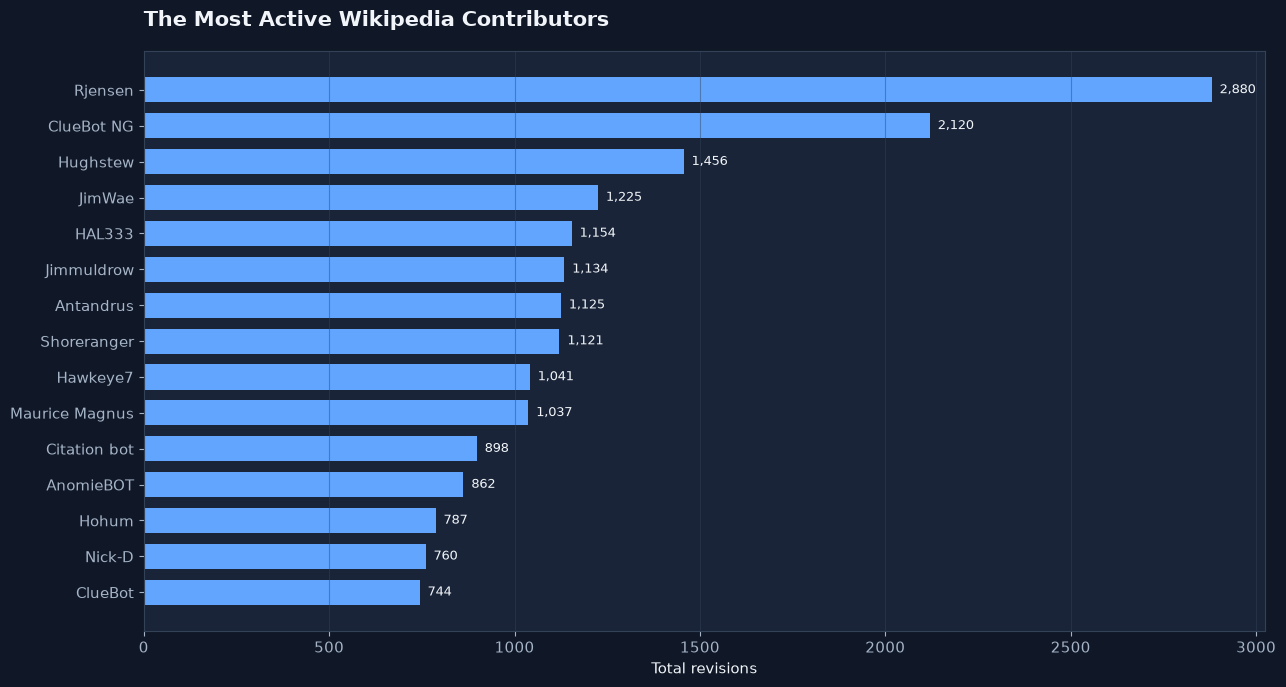

In [11]:

editor_activity = (
    df[df["username"] != "Unknown"]
    .groupby("username")
    .agg(
        revisions=("revision_id", "count"),
        articles=("article_title", "nunique"),
        first_edit=("timestamp", "min"),
        last_edit=("timestamp", "max")
    )
    .sort_values("revisions", ascending=False)
    .reset_index()
)

editor_activity["revision_percentage"] = (
    editor_activity["revisions"] / total_revisions * 100
)

display(editor_activity.head(20))

editor_activity.to_csv(
    RESULTS / "contributor_activity.csv",
    index=False
)

top_editors = editor_activity.head(15).sort_values("revisions")

fig, ax = plt.subplots(figsize=(13, 7))

bars = ax.barh(
    top_editors["username"],
    top_editors["revisions"],
    color=COLORS[1],
    height=0.7
)

for bar, value in zip(bars, top_editors["revisions"]):
    ax.text(
        value,
        bar.get_y() + bar.get_height() / 2,
        f"  {value:,}",
        va="center",
        fontsize=9
    )

ax.set_title(
    "The Most Active Wikipedia Contributors",
    loc="left",
    pad=18
)

ax.set_xlabel("Total revisions")
ax.grid(axis="x")

finish_plot(fig, "10_top_contributors.png")


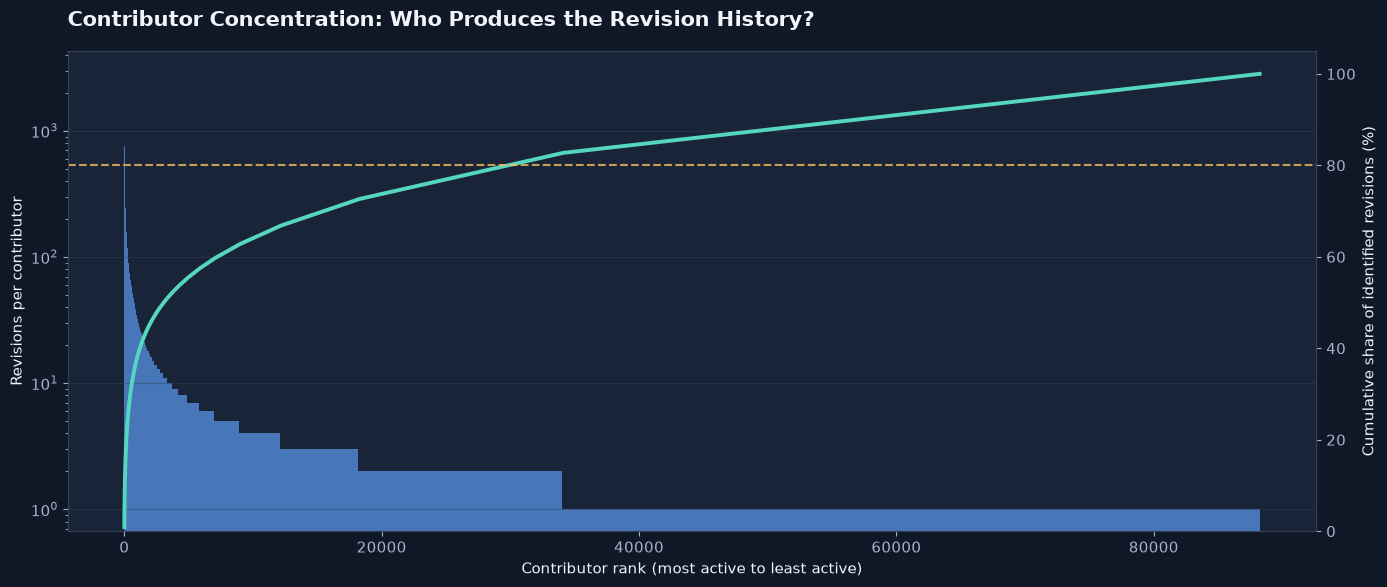

Top 1% contributor revision share: 36.71 %
Top 10% contributor revision share: 62.55 %
Contributors accounting for 50% of revisions: 3065


In [12]:

editor_counts = (
    df[df["username"] != "Unknown"]
    .groupby("username")
    .size()
    .sort_values(ascending=False)
)

editor_cumulative = editor_counts.cumsum() / editor_counts.sum() * 100

fig, ax1 = plt.subplots(figsize=(14, 6))

ranks = np.arange(1, len(editor_counts) + 1)

ax1.bar(
    ranks,
    editor_counts.values,
    color=COLORS[1],
    alpha=0.65,
    width=1
)

ax1.set_xlabel("Contributor rank (most active to least active)")
ax1.set_ylabel("Revisions per contributor")
ax1.set_title(
    "Contributor Concentration: Who Produces the Revision History?",
    loc="left",
    pad=18
)

ax1.set_yscale("log")
ax1.grid(axis="y")

ax2 = ax1.twinx()

ax2.plot(
    ranks,
    editor_cumulative.values,
    color=COLORS[0],
    linewidth=2.8
)

ax2.axhline(
    80,
    color=COLORS[2],
    linestyle="--",
    alpha=0.8
)

ax2.set_ylabel("Cumulative share of identified revisions (%)")
ax2.set_ylim(0, 105)

finish_plot(fig, "11_contributor_pareto.png")

# Calculate concentration metrics
editor_total = editor_counts.sum()

top_1_percent_count = max(1, int(np.ceil(len(editor_counts) * 0.01)))
top_10_percent_count = max(1, int(np.ceil(len(editor_counts) * 0.10)))

print(
    "Top 1% contributor revision share:",
    round(editor_counts.head(top_1_percent_count).sum() / editor_total * 100, 2),
    "%"
)

print(
    "Top 10% contributor revision share:",
    round(editor_counts.head(top_10_percent_count).sum() / editor_total * 100, 2),
    "%"
)

print(
    "Contributors accounting for 50% of revisions:",
    int(np.searchsorted(editor_cumulative.values, 50) + 1)
)


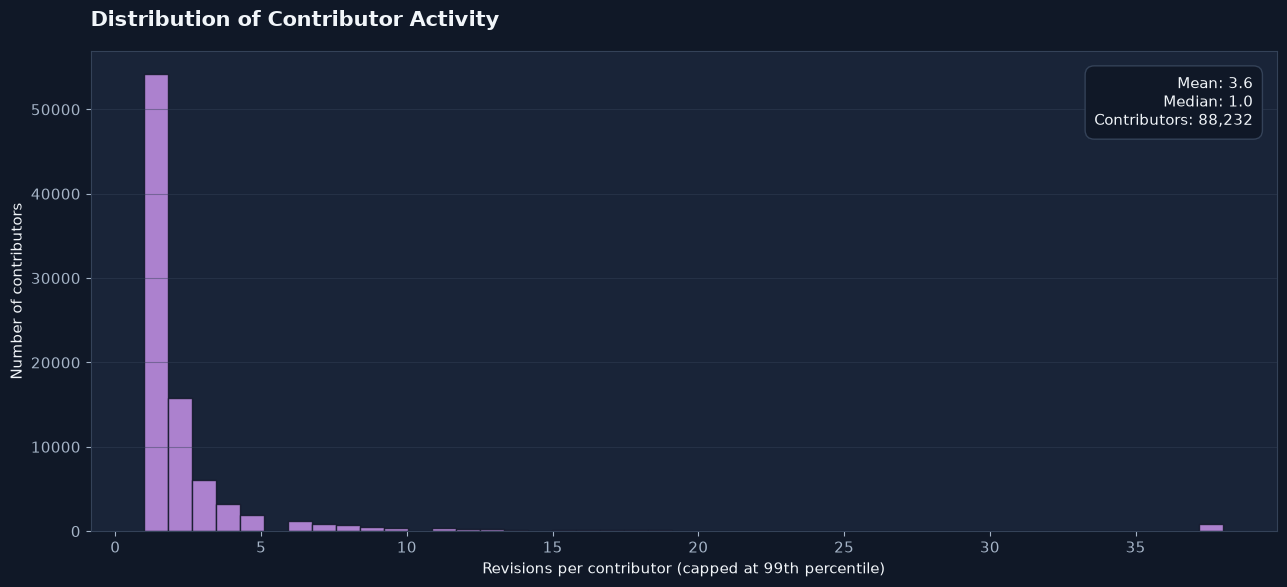

In [13]:

contributor_counts = (
    df[df["username"] != "Unknown"]
    .groupby("username")
    .size()
)

fig, ax = plt.subplots(figsize=(13, 6))

ax.hist(
    contributor_counts.clip(upper=contributor_counts.quantile(0.99)),
    bins=45,
    color=COLORS[3],
    alpha=0.85,
    edgecolor=BG
)

ax.set_title(
    "Distribution of Contributor Activity",
    loc="left",
    pad=18
)

ax.set_xlabel("Revisions per contributor (capped at 99th percentile)")
ax.set_ylabel("Number of contributors")
ax.grid(axis="y")

ax.text(
    0.98, 0.95,
    f"Mean: {contributor_counts.mean():.1f}\n"
    f"Median: {contributor_counts.median():.1f}\n"
    f"Contributors: {len(contributor_counts):,}",
    transform=ax.transAxes,
    ha="right",
    va="top",
    bbox=dict(
        boxstyle="round,pad=0.6",
        facecolor=BG,
        edgecolor=GRID
    )
)

finish_plot(fig, "12_contributor_distribution.png")


,identity_category,revisions,percentage
0,No public user ID,11,0.003511
1,Public user ID available,313258,99.996489


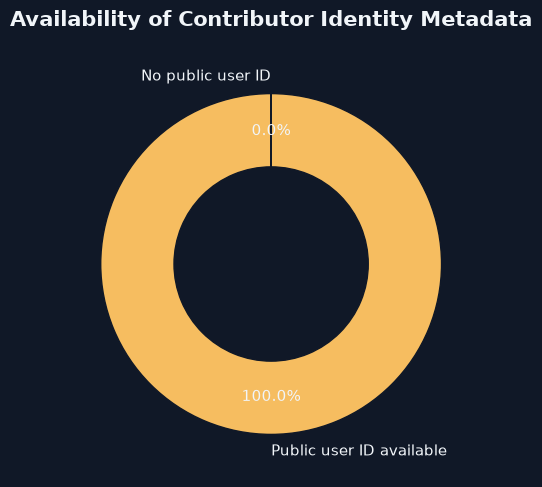

In [14]:

df["identity_category"] = np.where(
    df["user_id"].notna(),
    "Public user ID available",
    "No public user ID"
)

identity_summary = (
    df.groupby("identity_category")
    .size()
    .reset_index(name="revisions")
)

identity_summary["percentage"] = (
    identity_summary["revisions"] / len(df) * 100
)

display(identity_summary)

fig, ax = plt.subplots(figsize=(9, 5))

values = identity_summary["revisions"]
labels = identity_summary["identity_category"]

wedges, texts, autotexts = ax.pie(
    values,
    labels=labels,
    autopct="%1.1f%%",
    startangle=90,
    colors=[COLORS[0], COLORS[2]],
    wedgeprops={"width": 0.43, "edgecolor": BG},
    pctdistance=0.78
)

for text_item in texts + autotexts:
    text_item.set_color(TEXT)

ax.set_title(
    "Availability of Contributor Identity Metadata",
    pad=18
)

finish_plot(fig, "13_identity_metadata.png")


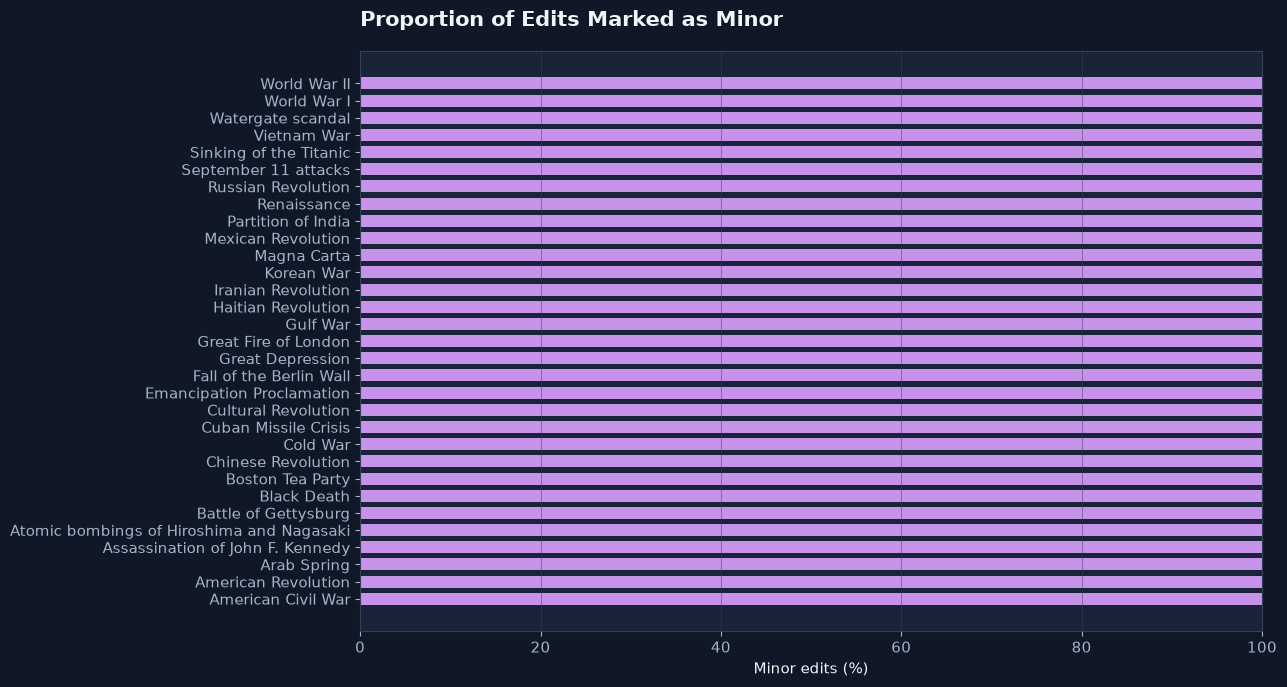

Overall minor edit percentage: 100.0 %


In [15]:

minor_summary = (
    df.groupby("article_title")
    .agg(
        total_edits=("revision_id", "count"),
        minor_edits=("is_minor", "sum")
    )
    .reset_index()
)

minor_summary["minor_percentage"] = (
    minor_summary["minor_edits"] /
    minor_summary["total_edits"] * 100
)

minor_summary = minor_summary.sort_values(
    "minor_percentage",
    ascending=True
)

fig, ax = plt.subplots(figsize=(13, 7))

bars = ax.barh(
    minor_summary["article_title"],
    minor_summary["minor_percentage"],
    color=COLORS[3],
    height=0.7
)

ax.set_title(
    "Proportion of Edits Marked as Minor",
    loc="left",
    pad=18
)

ax.set_xlabel("Minor edits (%)")
ax.set_xlim(0, 100)
ax.grid(axis="x")

finish_plot(fig, "14_minor_edit_comparison.png")

minor_summary.to_csv(
    RESULTS / "minor_edit_summary.csv",
    index=False
)

print(
    "Overall minor edit percentage:",
    round(df["is_minor"].mean() * 100, 2),
    "%"
)


C:\Users\Jackson\AppData\Local\Temp\ipykernel_31768\943907596.py:13: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  comments[category] = comments["edit_comment"].str.contains(


,Matching comments
Grammar / spelling,7172
Removal,8743
Formatting,12228
References / citations,12964
Expansion,14189
Reverting changes,51616


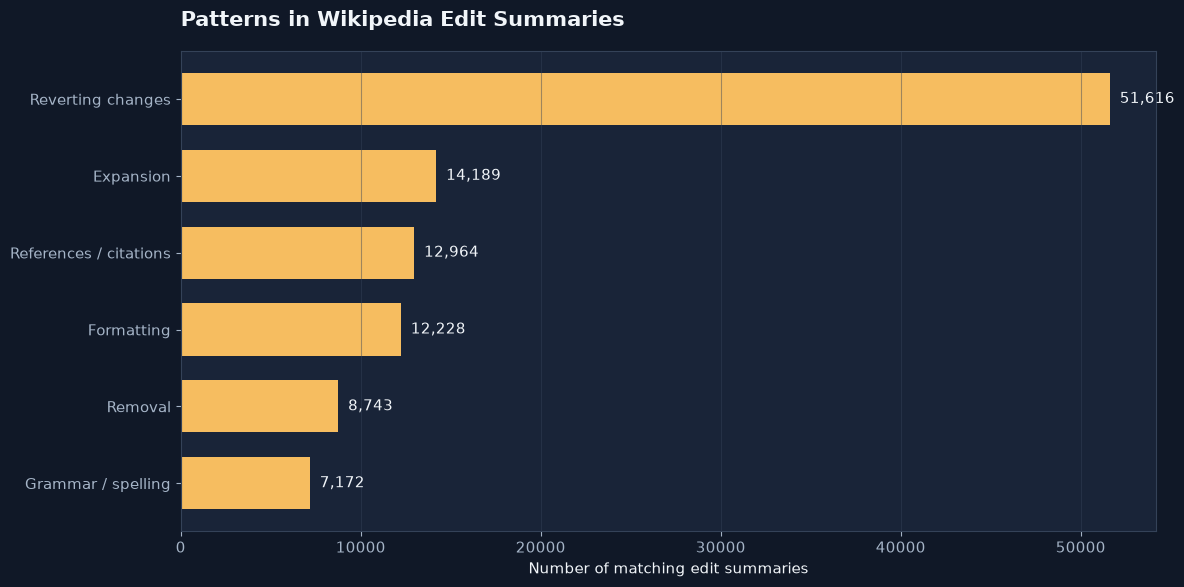

In [16]:

comments = df[df["edit_comment"].str.strip() != ""].copy()

comment_patterns = {
    "References / citations": r"\b(ref|refs|reference|citation|cite|source|sources)\b",
    "Reverting changes": r"\b(revert|reverted|undo|undid|rv|rollback)\b",
    "Grammar / spelling": r"\b(grammar|spell|spelling|typo|punctuation|copyedit)\b",
    "Formatting": r"\b(format|formatting|template|link|category|wikilink)\b",
    "Expansion": r"\b(add|added|expand|expanded|update|updated)\b",
    "Removal": r"\b(remove|removed|delete|deleted|cleanup)\b",
}

for category, pattern in comment_patterns.items():
    comments[category] = comments["edit_comment"].str.contains(
        pattern,
        flags=re.IGNORECASE,
        regex=True,
        na=False
    )

category_counts = pd.Series({
    category: comments[category].sum()
    for category in comment_patterns
}).sort_values()

display(category_counts.to_frame("Matching comments"))

fig, ax = plt.subplots(figsize=(12, 6))

bars = ax.barh(
    category_counts.index,
    category_counts.values,
    color=COLORS[2],
    height=0.68
)

for bar, value in zip(bars, category_counts.values):
    ax.text(
        value,
        bar.get_y() + bar.get_height() / 2,
        f"  {value:,}",
        va="center"
    )

ax.set_title(
    "Patterns in Wikipedia Edit Summaries",
    loc="left",
    pad=18
)

ax.set_xlabel("Number of matching edit summaries")
ax.grid(axis="x")

finish_plot(fig, "15_edit_summary_categories.png")

category_counts.to_csv(
    RESULTS / "edit_summary_categories.csv"
)


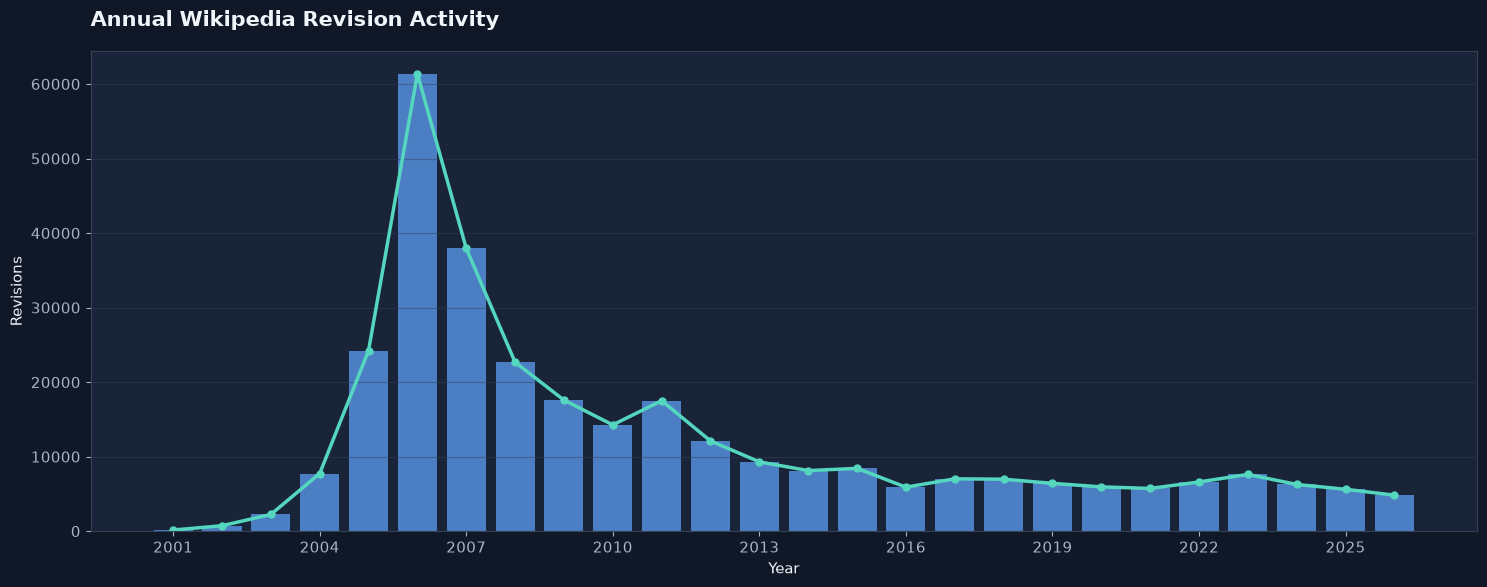

In [17]:

annual = (
    df.groupby(["year", "article_title"])
    .size()
    .rename("revisions")
    .reset_index()
)

annual_total = (
    annual.groupby("year")["revisions"]
    .sum()
)

fig, ax = plt.subplots(figsize=(15, 6))

ax.bar(
    annual_total.index,
    annual_total.values,
    color=COLORS[1],
    alpha=0.7,
    width=0.8
)

ax.plot(
    annual_total.index,
    annual_total.values,
    color=COLORS[0],
    linewidth=2.5,
    marker="o",
    markersize=5
)

ax.set_title(
    "Annual Wikipedia Revision Activity",
    loc="left",
    pad=18
)

ax.set_xlabel("Year")
ax.set_ylabel("Revisions")
ax.grid(axis="y")

ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))

finish_plot(fig, "16_annual_revision_activity.png")

annual.to_csv(
    RESULTS / "annual_article_activity.csv",
    index=False
)


,timestamp,revisions,rolling_average,unusual_activity
59,2006-04-01 00:00:00+00:00,7229,3492.250000,True
60,2006-05-01 00:00:00+00:00,6672,3890.666667,True
58,2006-03-01 00:00:00+00:00,6567,3037.166667,True
65,2006-10-01 00:00:00+00:00,5801,4988.000000,True
66,2006-11-01 00:00:00+00:00,5499,5154.750000,True
64,2006-09-01 00:00:00+00:00,5408,4717.250000,True
70,2007-03-01 00:00:00+00:00,5146,5022.750000,True
71,2007-04-01 00:00:00+00:00,4977,4835.083333,True
68,2007-01-01 00:00:00+00:00,4814,5153.583333,True
57,2006-02-01 00:00:00+00:00,4713,2581.666667,True


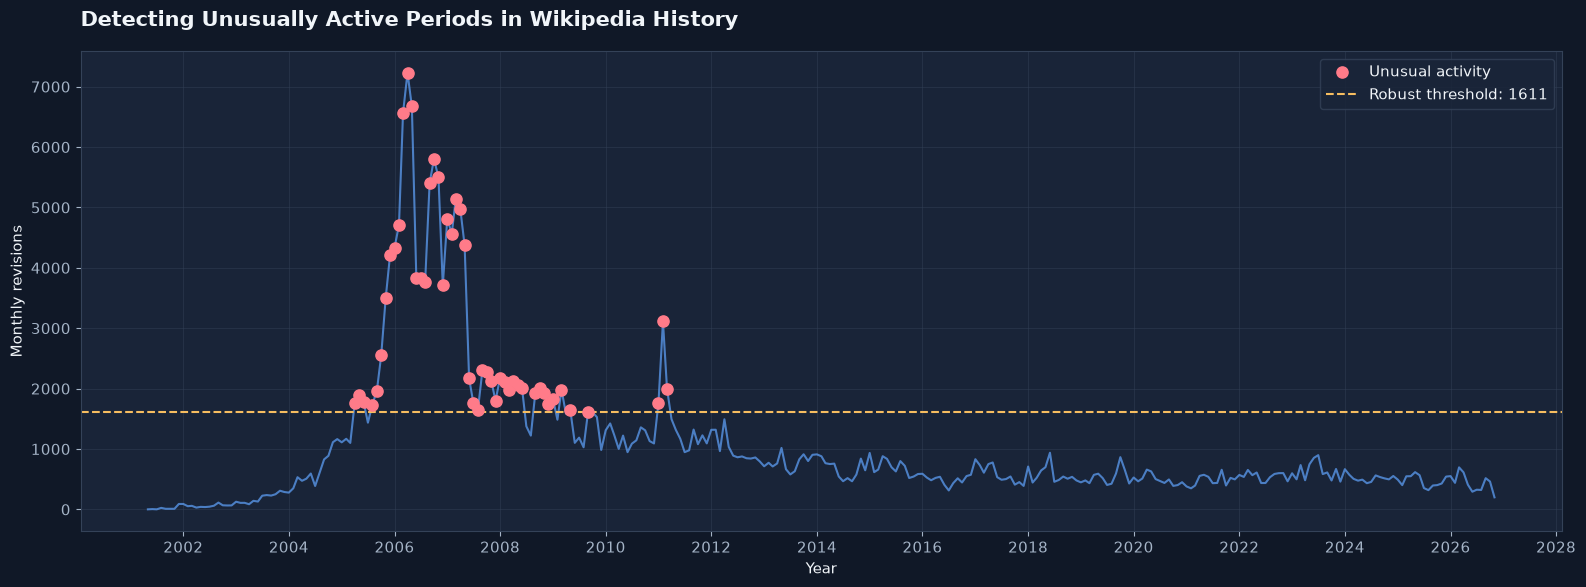

In [18]:

activity = monthly.copy()

median_activity = activity["revisions"].median()

mad = np.median(
    np.abs(activity["revisions"] - median_activity)
)

# Robust outlier threshold
threshold = median_activity + 3 * 1.4826 * mad

activity["unusual_activity"] = (
    activity["revisions"] > threshold
)

unusual_months = activity[
    activity["unusual_activity"]
].sort_values(
    "revisions",
    ascending=False
)

display(unusual_months)

fig, ax = plt.subplots(figsize=(16, 6))

normal = activity[~activity["unusual_activity"]]
unusual = activity[activity["unusual_activity"]]

ax.plot(
    activity["timestamp"],
    activity["revisions"],
    color=COLORS[1],
    alpha=0.7,
    linewidth=1.5
)

ax.scatter(
    unusual["timestamp"],
    unusual["revisions"],
    color=COLORS[4],
    s=65,
    zorder=3,
    label="Unusual activity"
)

ax.axhline(
    threshold,
    color=COLORS[2],
    linestyle="--",
    label=f"Robust threshold: {threshold:.0f}"
)

ax.set_title(
    "Detecting Unusually Active Periods in Wikipedia History",
    loc="left",
    pad=18
)

ax.set_xlabel("Year")
ax.set_ylabel("Monthly revisions")
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

ax.grid()
ax.legend()

finish_plot(fig, "17_unusual_activity_periods.png")

unusual_months.to_csv(
    RESULTS / "unusual_activity_periods.csv",
    index=False
)


In [19]:

article_comparison = (
    df.groupby("article_title")
    .agg(
        total_revisions=("revision_id", "count"),
        unique_editors=("username", lambda x: x[x != "Unknown"].nunique()),
        earliest_revision=("timestamp", "min"),
        latest_revision=("timestamp", "max"),
        average_size_bytes=("article_size_bytes", "mean"),
        maximum_size_bytes=("article_size_bytes", "max"),
        minimum_size_bytes=("article_size_bytes", "min"),
        median_size_bytes=("article_size_bytes", "median"),
        average_absolute_change=("absolute_size_change", "mean"),
        largest_change=("absolute_size_change", "max"),
        minor_edit_rate=("is_minor", "mean")
    )
    .reset_index()
)

article_comparison["coverage_years"] = (
    article_comparison["latest_revision"] -
    article_comparison["earliest_revision"]
).dt.days / 365.25

article_comparison["revisions_per_year"] = (
    article_comparison["total_revisions"] /
    article_comparison["coverage_years"].replace(0, np.nan)
)

article_comparison["minor_edit_rate"] *= 100

article_comparison = article_comparison.sort_values(
    "total_revisions",
    ascending=False
)

display(
    article_comparison.style.format({
        "average_size_bytes": "{:,.0f}",
        "maximum_size_bytes": "{:,.0f}",
        "minimum_size_bytes": "{:,.0f}",
        "median_size_bytes": "{:,.0f}",
        "average_absolute_change": "{:,.1f}",
        "largest_change": "{:,.0f}",
        "minor_edit_rate": "{:.1f}%",
        "coverage_years": "{:.1f}",
        "revisions_per_year": "{:,.1f}"
    })
)

article_comparison.to_csv(
    RESULTS / "article_comparison_metrics.csv",
    index=False
)


,article_title,total_revisions,unique_editors,earliest_revision,latest_revision,average_size_bytes,maximum_size_bytes,minimum_size_bytes,median_size_bytes,average_absolute_change,largest_change,minor_edit_rate,coverage_years,revisions_per_year
30,World War II,28609,8826,2001-11-10 00:51:27+00:00,2026-11-10 01:56:48+00:00,"131,396","1,613,424",0,"113,636","3,715.1","1,524,224",100.0%,25.0,"1,144.4"
25,September 11 attacks,22585,6755,2001-11-21 16:01:18+00:00,2026-11-08 04:06:59+00:00,"123,665","406,473",0,"105,070","1,921.9","328,726",100.0%,25.0,904.8
29,World War I,20277,7460,2001-10-27 23:43:06+00:00,2026-11-08 07:12:00+00:00,"154,132","2,716,074",0,"111,246","3,929.3","2,642,330",100.0%,25.0,810.1
27,Vietnam War,19378,5353,2001-11-01 06:35:01+00:00,2026-11-07 02:30:28+00:00,"172,207","406,531",0,"133,980","2,253.5","328,224",100.0%,25.0,774.7
3,Assassination of John F. Kennedy,15182,5755,2003-08-02 05:53:22+00:00,2026-11-08 16:12:46+00:00,"82,602","1,793,519",0,"83,125","1,972.6","1,716,907",100.0%,23.3,652.5
0,American Civil War,14930,4501,2001-11-02 23:28:55+00:00,2026-11-09 17:51:56+00:00,"125,104","514,913",0,"104,057","2,191.7","412,781",100.0%,25.0,596.8
19,Korean War,14749,5127,2001-08-02 03:45:51+00:00,2026-11-08 06:54:49+00:00,"147,031","528,247",0,"124,148","1,630.8","474,099",100.0%,25.3,583.7
16,Gulf War,14132,6420,2001-08-07 17:52:24+00:00,2026-11-09 07:38:32+00:00,"126,210","739,932",0,"107,072","2,754.2","647,443",100.0%,25.3,559.6
9,Cold War,12602,4273,2003-09-23 04:44:46+00:00,2026-10-23 06:27:29+00:00,"105,837","336,667",0,"72,719","1,581.6","256,503",100.0%,23.1,545.9
14,Great Depression,11555,5213,2001-09-16 16:22:31+00:00,2026-11-07 20:34:57+00:00,"54,843","269,575",0,"35,526","2,274.6","216,867",100.0%,25.1,459.6


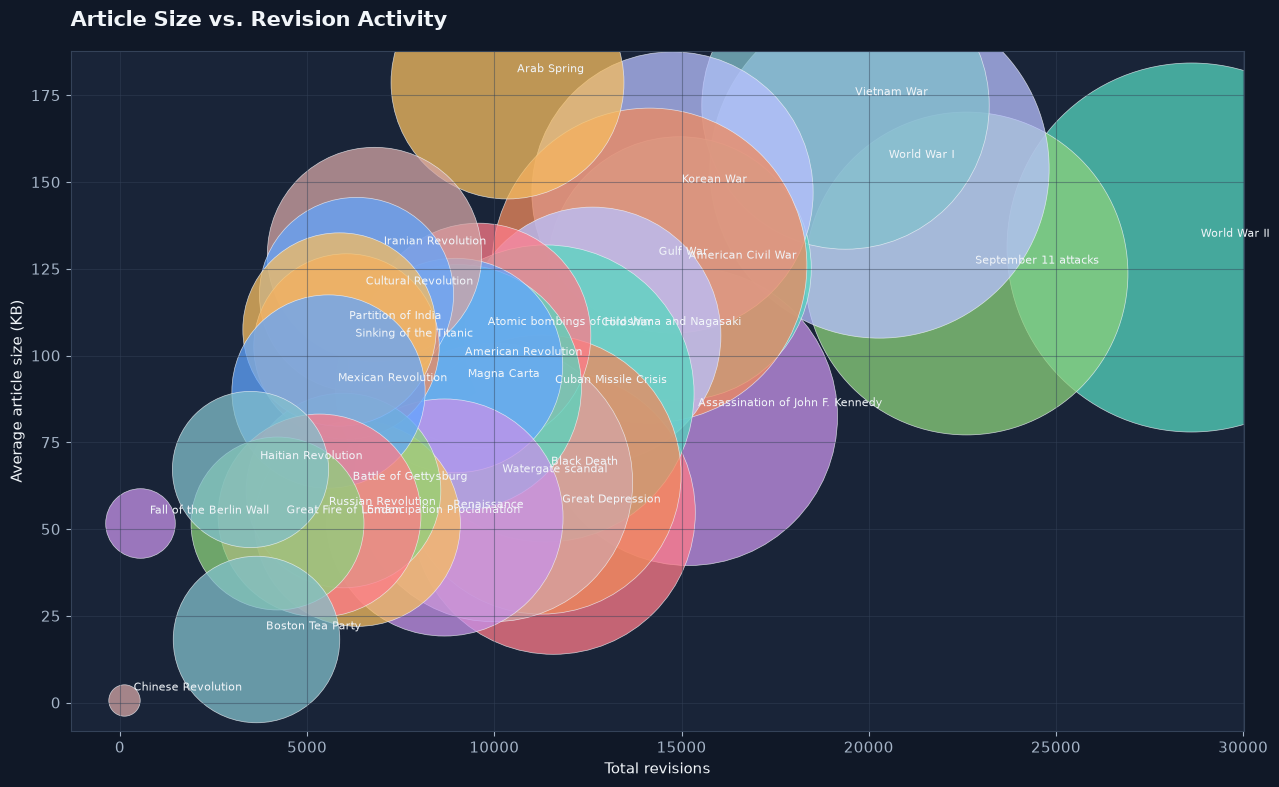

In [20]:

scatter_data = article_comparison.copy()

scatter_data["bubble_size"] = (
    scatter_data["unique_editors"].clip(lower=1) * 8
)

fig, ax = plt.subplots(figsize=(13, 8))

for i, row in scatter_data.iterrows():
    ax.scatter(
        row["total_revisions"],
        row["average_size_bytes"] / 1000,
        s=row["bubble_size"],
        color=COLORS[i % len(COLORS)],
        alpha=0.75,
        edgecolors=TEXT,
        linewidths=0.5
    )

    ax.annotate(
        row["article_title"],
        (
            row["total_revisions"],
            row["average_size_bytes"] / 1000
        ),
        xytext=(7, 7),
        textcoords="offset points",
        fontsize=8,
        color=TEXT
    )

ax.set_title(
    "Article Size vs. Revision Activity",
    loc="left",
    pad=18
)

ax.set_xlabel("Total revisions")
ax.set_ylabel("Average article size (KB)")

ax.grid()

finish_plot(fig, "18_article_size_vs_activity.png")


In [21]:

most_edited = article_comparison.iloc[0]

largest_article = article_comparison.loc[
    article_comparison["average_size_bytes"].idxmax()
]

most_contributors = article_comparison.loc[
    article_comparison["unique_editors"].idxmax()
]

highest_minor = article_comparison.loc[
    article_comparison["minor_edit_rate"].idxmax()
]

overall_median = df["article_size_bytes"].median()
overall_mean = df["article_size_bytes"].mean()

identified_editor_share = (
    (df["username"] != "Unknown").mean() * 100
)

findings = [
    (
        "Dataset scale",
        f"The dataset contains {total_revisions:,} revisions "
        f"across {total_articles:,} articles."
    ),
    (
        "Most edited article",
        f"{most_edited['article_title']} has "
        f"{most_edited['total_revisions']:,} collected revisions."
    ),
    (
        "Largest average article",
        f"{largest_article['article_title']} has the largest "
        f"average revision size at "
        f"{largest_article['average_size_bytes']:,.0f} bytes."
    ),
    (
        "Contributor participation",
        f"{most_contributors['article_title']} has the most "
        f"identified contributors "
        f"({most_contributors['unique_editors']:,})."
    ),
    (
        "Minor edit patterns",
        f"{highest_minor['article_title']} has the highest "
        f"proportion of edits marked minor "
        f"({highest_minor['minor_edit_rate']:.1f}%)."
    ),
    (
        "Contributor metadata",
        f"{identified_editor_share:.1f}% of revisions have "
        f"a username other than Unknown."
    ),
    (
        "Article size",
        f"The median revision size is {overall_median:,.0f} bytes "
        f"and the mean is {overall_mean:,.0f} bytes."
    ),
    (
        "Unusual activity",
        f"{len(unusual_months):,} months exceed the "
        f"robust unusual-activity threshold."
    )
]

for title, description in findings:
    print(f"\n{title.upper()}")
    print(description)

with open(
    RESULTS / "preliminary_findings.txt",
    "w",
    encoding="utf-8"
) as file:
    for title, description in findings:
        file.write(f"{title}\n{description}\n\n")




DATASET SCALE
The dataset contains 313,269 revisions across 31 articles.

MOST EDITED ARTICLE
World War II has 28,609 collected revisions.

LARGEST AVERAGE ARTICLE
Arab Spring has the largest average revision size at 178,833 bytes.

CONTRIBUTOR PARTICIPATION
World War II has the most identified contributors (8,826).

MINOR EDIT PATTERNS
World War II has the highest proportion of edits marked minor (100.0%).

CONTRIBUTOR METADATA
100.0% of revisions have a username other than Unknown.

ARTICLE SIZE
The median revision size is 91,937 bytes and the mean is 109,681 bytes.

UNUSUAL ACTIVITY
49 months exceed the robust unusual-activity threshold.


In [22]:

# Save the cleaned analysis dataset with recalculated fields
df.to_csv(
    RESULTS / "analysis_dataset.csv",
    index=False
)

# Save the final comparison table
article_comparison.to_csv(
    RESULTS / "article_comparison_metrics.csv",
    index=False
)

# Save overall activity
monthly.to_csv(
    RESULTS / "overall_monthly_activity.csv",
    index=False
)

# Save article growth
growth.to_csv(
    RESULTS / "quarterly_article_growth.csv",
    index=False
)

# Save the preliminary findings
print("\nANALYSIS EXPORT COMPLETE")

print(f"Figures generated: {len(list(FIGURES.glob('*.png')))}")
print(f"Analysis files: {len(list(RESULTS.glob('*.csv'))) + len(list(RESULTS.glob('*.txt')))}")

print("\nFigure directory:", FIGURES.resolve())
print("Results directory:", RESULTS.resolve())



ANALYSIS EXPORT COMPLETE
Figures generated: 24
Analysis files: 27

Figure directory: C:\Users\Jackson\Desktop\class\arch\finalProject\analysis\figures
Results directory: C:\Users\Jackson\Desktop\class\arch\finalProject\analysis\analysis_results
